# Sarcasm Detection using NLP

In [1]:
import os

IS_ON_COLAB = bool(os.getenv("COLAB_RELEASE_TAG"))

if IS_ON_COLAB:
    !pip install transformers==4.28.0
    !pip install tokenizers datasets sentencepiece huggingface_hub[cli] accelerate loralib peft

    from google.colab import drive
    drive.mount('/content/drive')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.0/7.0 MB 18.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.8/268.8 kB 26.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 42.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 519.6/519.6 kB 7.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 14.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 251.2/251.2 kB 15.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.6/85.6 kB 12.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.3/115.3 kB 12.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 194.1/194.1 kB 12.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 134.8/134.8 kB 16.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.7/67.7 kB 8.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 25.5 MB/s eta 0:00:00
Mounted at /content/drive


In [2]:
# import functions
from functions import *

In [3]:
# import basic libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# import torch
import torch
from torch import nn

# import sklearn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, f1_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import GridSearchCV

# import transformers
from transformers import AutoTokenizer, AutoModel, Trainer, TrainingArguments, AutoModelForSequenceClassification, AutoConfig, DataCollatorWithPadding

# import others
from datasets import DatasetDict, Dataset, Features, ClassLabel
from peft import get_peft_model, LoraConfig



## Data Preparation

In [4]:
# read in the data
if IS_ON_COLAB:
    headline = pd.read_json('/content/drive/MyDrive/Colab Notebooks/final-project-clchenlin/Sarcasm_Headlines_Dataset.json',lines=True)
else:
    headline = pd.read_json('Sarcasm_Headlines_Dataset.json',lines=True)

In [5]:
# preprocess headline data
headline = preprocess(headline)
headline.head(5)

,text,label
0,steve wilson on 'the making of gone with the w...,0
1,standards lowered for second search through fr...,1
2,surgical tech in needle-swap scandal at swedis...,0
3,ferguson is not among the most dangerous place...,0
4,bill clinton resting up to sit upright at next...,1


In [6]:
headline.shape

(26709, 2)

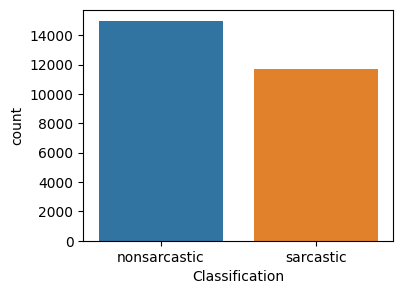

0    0.561047
1    0.438953
Name: label, dtype: float64


In [7]:
# create plot to check for class imbalance
plot_class(headline)
print(headline['label'].value_counts(normalize=True).sort_index())

In [8]:
seed_value = 123
# split the DataFrame into train, validation, and test sets
train_df, temp_df = train_test_split(headline, test_size=0.3, random_state=seed_value)
valid_df, test_df = train_test_split(temp_df, test_size=0.5, random_state=seed_value)

# convert DataFrames into datasets
train_dataset = Dataset.from_pandas(train_df)
valid_dataset = Dataset.from_pandas(valid_df)
test_dataset = Dataset.from_pandas(test_df)

In [9]:
# create a DatasetDict to organize the datasets
headline_dict = DatasetDict({'train': train_dataset, 'validation': valid_dataset, 'test': test_dataset})
headline_dict = headline_dict.remove_columns(["__index_level_0__"])

# create class labels
features = Features({'label': ClassLabel(num_classes=2, names=['nonsarcastic', 'sarcastic'])})
headline_dict.features = features

In [10]:
# specify label mappings
id2label = {idx:features["label"].int2str(idx) for idx in range(2)}
label2id = {v:k for k,v in id2label.items()}
print(id2label)
print(label2id)

{0: 'nonsarcastic', 1: 'sarcastic'}
{'nonsarcastic': 0, 'sarcastic': 1}


## Feature Extraction
This section uses feature extraction to classify whether a headline is sarcastic or not. To improve the performance of the model, I've considered the following approaches:
1. trying different post-processing:
   + average over token dimension
   + keep the hidden state vector for the first token
   + keep the hidden state vector for the last valid token
2. trying different classification models
   + Logistic regression
   + Random Forest
3. tuning hyperparameters of classfication models

In [11]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [12]:
# encode headline
model_name = "microsoft/MiniLM-L12-H384-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)
headline_encoded = encode(headline_dict, tokenizer)

Map:   0%|          | 0/18696 [00:00<?, ? examples/s]

Map:   0%|          | 0/4006 [00:00<?, ? examples/s]

Map:   0%|          | 0/4007 [00:00<?, ? examples/s]

In [13]:
model = AutoModel.from_pretrained(model_name).to(device)

last_states_list = []
# for each different postprocessing method
# extract last hidden states from encoded dataset
for post in ['average', 'last', 'first']:
    last_states = headline_encoded.map(
    extract_states,
    batched=True,
    batch_size=100,
    fn_kwargs={"model": model,
               "postprocess": post,
               "device": device},
)
    last_states_list.append(last_states)


last_states_df = pd.DataFrame([last_states_list])
last_states_df.columns = ['average', 'last', 'first']
last_states_df

Map:   0%|          | 0/18696 [00:00<?, ? examples/s]

/content/functions.py:92: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  input_ids = torch.tensor(batch["input_ids"]).to(device)
/content/functions.py:93: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  attention_mask = torch.tensor(batch["attention_mask"]).to(device)


Map:   0%|          | 0/4006 [00:00<?, ? examples/s]

Map:   0%|          | 0/4007 [00:00<?, ? examples/s]

Map:   0%|          | 0/18696 [00:00<?, ? examples/s]

Map:   0%|          | 0/4006 [00:00<?, ? examples/s]

Map:   0%|          | 0/4007 [00:00<?, ? examples/s]

Map:   0%|          | 0/18696 [00:00<?, ? examples/s]

Map:   0%|          | 0/4006 [00:00<?, ? examples/s]

Map:   0%|          | 0/4007 [00:00<?, ? examples/s]

,average,last,first
0,{'train': ({'text': 'rachael ray snaps chicken...,{'train': ({'text': 'rachael ray snaps chicken...,{'train': ({'text': 'rachael ray snaps chicken...


In [14]:
# empty list to store the best hyperparameters and accuracy of Logistic Regression
logit_result = []
# empty list to store the best hyperparameters and accuracy of Random Forest
rf_result = []

# tuning hyperparameters of Logistic Regression and Random Forest for different postprocessing methods
for index, post in enumerate(last_states_df.columns.tolist()):
    X_train = np.array(last_states_df[post].iloc[0]["train"]["hidden_state"])
    X_test = np.array(last_states_df[post].iloc[0]["test"]["hidden_state"])
    y_train = np.array(last_states_df[post].iloc[0]["train"]["label"])
    y_test = np.array(last_states_df[post].iloc[0]["test"]["label"])

    # use Logistic Regression as classification model
    # create a parameter grid to search over
    param_grid_logit = {
        "penalty": ["l2"],
        "max_iter": [1000, 3000],
        "C": [0.1, 1, 10],
    }
    # create GridSearchCV
    grid_search_logit = GridSearchCV(
        LogisticRegression(
            fit_intercept=True,
            solver='sag',
            n_jobs=-1
        ),
        param_grid_logit,
        cv=4,
        scoring='f1_macro'
    )
    # tune hyperparameters of Logistic Regression
    grid_search_logit.fit(X_train, y_train)
    # calculate accuracy of best model on test set
    test_score_logit = grid_search_logit.best_estimator_.score(X_test, y_test)

    logit_result.append({'Post': post,
                        'best parameters': grid_search_logit.best_params_,
                        'best f1 scores': grid_search_logit.best_score_,
                        'test f1 scores of best model': test_score_logit})

    # use Random Forest Classifier as classification model
    # create a parameter grid to search over
    param_grid_rf = {
        'n_estimators': [100],
        'max_depth': [10],
        'min_samples_split': [3, 6]
    }
    # create GridSearchCV
    grid_search_rf = GridSearchCV(RandomForestClassifier(random_state=seed_value,
                                                         n_jobs=-1),
                                    param_grid_rf,
                                    cv=4,
                                    scoring='f1_macro')

    # tune hyperparameters of Random Forest
    grid_search_rf.fit(X_train, y_train)
    # calculate accuracy of best model on test set
    test_score_rf = grid_search_rf.best_estimator_.score(X_test, y_test)

    rf_result.append({'Post': post,
                    'best parameters': grid_search_rf.best_params_,
                    'best f1 scores': grid_search_rf.best_score_,
                    'test f1 scores of best model': test_score_rf})

logit_df = pd.DataFrame(logit_result)
rf_df = pd.DataFrame(rf_result)

/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which 

In [15]:
# print the results of hyperparameter tuning
print(logit_df)
print(rf_df)

      Post                               best parameters  best f1 scores  \
0  average  {'C': 10, 'max_iter': 1000, 'penalty': 'l2'}        0.877747   
1     last  {'C': 10, 'max_iter': 3000, 'penalty': 'l2'}        0.846333   
2    first  {'C': 10, 'max_iter': 1000, 'penalty': 'l2'}        0.846337   

   test f1 scores of best model  
0                      0.889943  
1                      0.853257  
2                      0.853257  
      Post                                    best parameters  best f1 scores  \
0  average  {'max_depth': 10, 'min_samples_split': 6, 'n_e...        0.824203   
1     last  {'max_depth': 10, 'min_samples_split': 6, 'n_e...        0.803200   
2    first  {'max_depth': 10, 'min_samples_split': 6, 'n_e...        0.801590   

   test f1 scores of best model  
0                      0.825555  
1                      0.811330  
2                      0.808585  


With feature extraction, the best model performance is achieved by averaging over token dimension and using a Logistic Regression as classification head.

## Fine-Tuning
This section uses fine-tuning to classify whether a headline is sarcastic or not. To improve the performance of the model, I've addressed the data imbalance by incorporating class weights in the loss function.

### Address the data imbalance

In [ ]:
# rename label column and remove unnecessary columns
headline_encoded = headline_encoded.rename_column("label", "labels")
headline_encoded = headline_encoded.remove_columns(["text", "token_type_ids"])

In [ ]:
# address data imbalance
class_weights = (1 - (headline['label'].value_counts().sort_index() / len(headline))).values
class_weights = torch.from_numpy(class_weights).float().to("cuda")

In [ ]:
# create a subclass to custom the behavior of loss computation
class WeightedLossTrainer(Trainer):
  def compute_loss(self, model, inputs, return_outputs=False):
    # feed inputs to model and extract logits
    outputs = model(**inputs)
    logits = outputs.get("logits")
    # extract labels
    labels = input.get("labels")
    # define loss function with class weights
    loss_func = nn.CrossEntropyLoss(weight=class_weights)
    # compute loss
    loss = loss_func(logits, labels)
    return (loss, outputs) if return_outputs else loss


### Set up the model

In [ ]:
model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2,
    id2label=id2label,
    label2id=label2id
).to(device)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at microsoft/MiniLM-L12-H384-uncased and are newly initialized: ['classifier.weight', 'classifier.bias']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


### Set up the training argument

In [ ]:
batch_size = 8
logging_steps = len(headline_encoded["train"]) // batch_size

In [ ]:
training_args = TrainingArguments(
    output_dir="results",
    optim='adamw_torch',
    per_device_train_batch_size=batch_size,
    per_device_eval_batch_size=batch_size,
    num_train_epochs=3,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    evaluation_strategy="epoch",
    save_strategy="epoch",
    disable_tqdm=False,
    fp16=True,
    logging_steps=logging_steps,
)

In [ ]:
trainer = Trainer(
    model=model,
    args=training_args,
    compute_metrics=compute_metrics,
    train_dataset=headline_encoded["train"],
    eval_dataset=headline_encoded["validation"]
)

### Training

In [ ]:
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.334800,0.304209,0.911133,0.910779
2,0.201400,0.303224,0.927858,0.927755
3,0.112800,0.319621,0.931852,0.931706


TrainOutput(global_step=7011, training_loss=0.21633452346229362, metrics={'train_runtime': 518.4738, 'train_samples_per_second': 108.179, 'train_steps_per_second': 13.522, 'total_flos': 476266014278208.0, 'train_loss': 0.21633452346229362, 'epoch': 3.0})

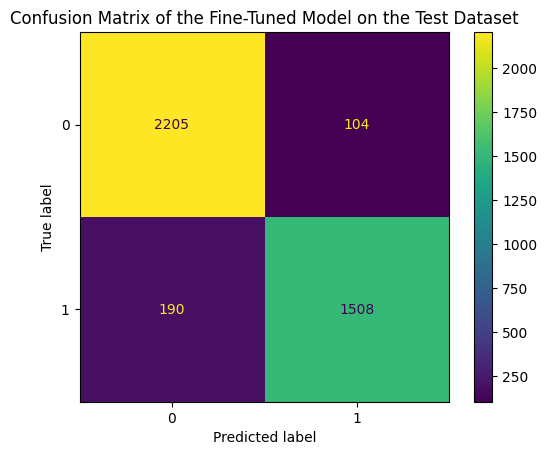

In [ ]:
# apply the fine-tuned model to the test dataset
y_preds = apply_to_test(trainer, headline_encoded["test"])
y_true = headline_encoded["test"]["labels"]

# plot confusion matrix
plot_confusion_matrix(y_true,
                    y_preds,
                    [0,1],
                    'Confusion Matrix of the Fine-Tuned Model on the Test Dataset')

In [ ]:
# classification report
print(classification_report(y_true, y_preds))

              precision    recall  f1-score   support

           0       0.92      0.95      0.94      2309
           1       0.94      0.89      0.91      1698

    accuracy                           0.93      4007
   macro avg       0.93      0.92      0.92      4007
weighted avg       0.93      0.93      0.93      4007



# Fine-tuning with PEFT and LoRA

### Set up the model

In [ ]:
model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2,
    return_dict=True
).to(device)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at microsoft/MiniLM-L12-H384-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [ ]:
# freezing the original weights
for param in model.parameters():
  param.requires_grad = False
  if param.ndim == 1:
    param.data = param.data.to(torch.float32)

model.gradient_checkpointing_enable()
model.enable_input_require_grads()

In [ ]:
config = LoraConfig(
    lora_alpha=16, #alpha scaling
    lora_dropout=0.1,
    task_type="SEQ_CLS",
)

model_peft = get_peft_model(model, config)
print_trainable_parameters(model_peft)

trainable params: 148996 || all params: 33508996 || trainable%: 0.4446447753910622


### Set up the collator, and the training arguments

In [ ]:
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
batch_size = 8
logging_steps = len(headline_encoded["train"]) // batch_size

In [ ]:
training_args = TrainingArguments(
    output_dir="results",
    optim='adamw_torch',
    learning_rate=3e-4,
    per_device_train_batch_size=batch_size,
    per_device_eval_batch_size=batch_size,
    num_train_epochs=3,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    evaluation_strategy="epoch",
    save_strategy="epoch"
)

In [ ]:
trainer_peft = Trainer(
    model=model_peft,
    args=training_args,
    compute_metrics=compute_metrics,
    train_dataset=headline_encoded["train"],
    eval_dataset=headline_encoded["validation"],
    tokenizer=tokenizer,
    data_collator=data_collator,
)

### Training

In [ ]:
trainer_peft.train()

You're using a BertTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.281700,0.217192,0.913630,0.913367
2,0.236100,0.212716,0.920120,0.919883
3,0.217300,0.227702,0.919621,0.919269


TrainOutput(global_step=7011, training_loss=0.2665325324828845, metrics={'train_runtime': 539.9443, 'train_samples_per_second': 103.877, 'train_steps_per_second': 12.985, 'total_flos': 479558239433856.0, 'train_loss': 0.2665325324828845, 'epoch': 3.0})

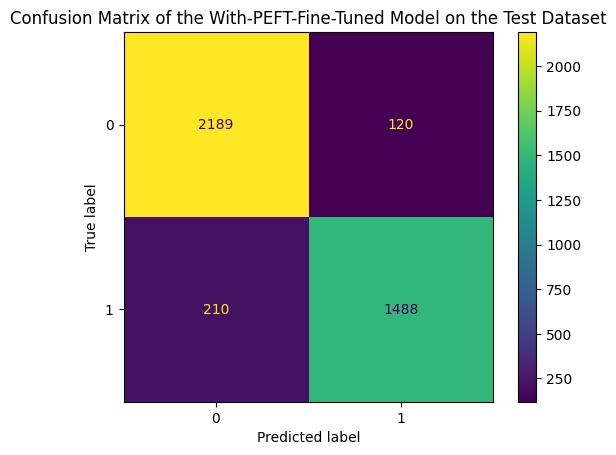

In [ ]:
# apply the fine-tuned model to the test dataset
y_preds = apply_to_test(trainer_peft, headline_encoded["test"])
y_true = headline_encoded["test"]["label"]

# plot confusion matrix
plot_confusion_matrix(y_true,
                    y_preds,
                    [0,1],
                    'Confusion Matrix of the With-PEFT-Fine-Tuned Model on the Test Dataset')

In [ ]:
# classification report
print(classification_report(y_true, y_preds))

              precision    recall  f1-score   support

           0       0.91      0.95      0.93      2309
           1       0.93      0.88      0.90      1698

    accuracy                           0.92      4007
   macro avg       0.92      0.91      0.92      4007
weighted avg       0.92      0.92      0.92      4007



## Using fine-tuned model from Hugging Face

In [17]:
from transformers import pipeline

classifier = pipeline("text-classification", model="jkhan447/sarcasm-detection-RoBerta-base-CR")

In [18]:
model_output = pd.DataFrame(classifier(headline_dict["test"]["text"]))

# replace output label
replacements = {
    "LABEL_0": 0,
    "LABEL_1": 1,
}

y_pred = model_output["label"].replace(replacements).to_numpy()

# true label
y_test = np.array(headline_dict["test"]["label"])

# classification report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.58      0.50      0.53      2309
           1       0.43      0.51      0.46      1698

    accuracy                           0.50      4007
   macro avg       0.50      0.50      0.50      4007
weighted avg       0.51      0.50      0.50      4007

